# 03 - Cross-correlation and inter-detector time lags

A GW signal arrives at each detector with a delay bounded by the light-travel time between them
(L1-H1 ~ 10 ms, L1-V1 ~ 26 ms, H1-V1 ~ 27 ms). We estimate the lag from the peak of the cross-correlation, searching
only inside that physical window, using three inputs:

1. the **whitened data**,
2. **IMF1** of the data (EMD removes slower, noise-dominated components),
3. the **noise-free whitened signal** - this is the *reference* the other two are compared against.

In [1]:
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import numpy as np
import matplotlib.pyplot as plt
from gwhht.config import load_config
from gwhht.simulate import simulate_network
from gwhht.preprocess import preprocess_network
%matplotlib inline
from gwhht.pipeline import run_single
from gwhht import plotting as P

In [2]:
cfg = load_config("../configs/default.yaml")
res = run_single(cfg)
a, m = res.artifacts, res.metrics
print(f"network SNR = {m['snr_network']:.1f}")

network SNR = 56.6


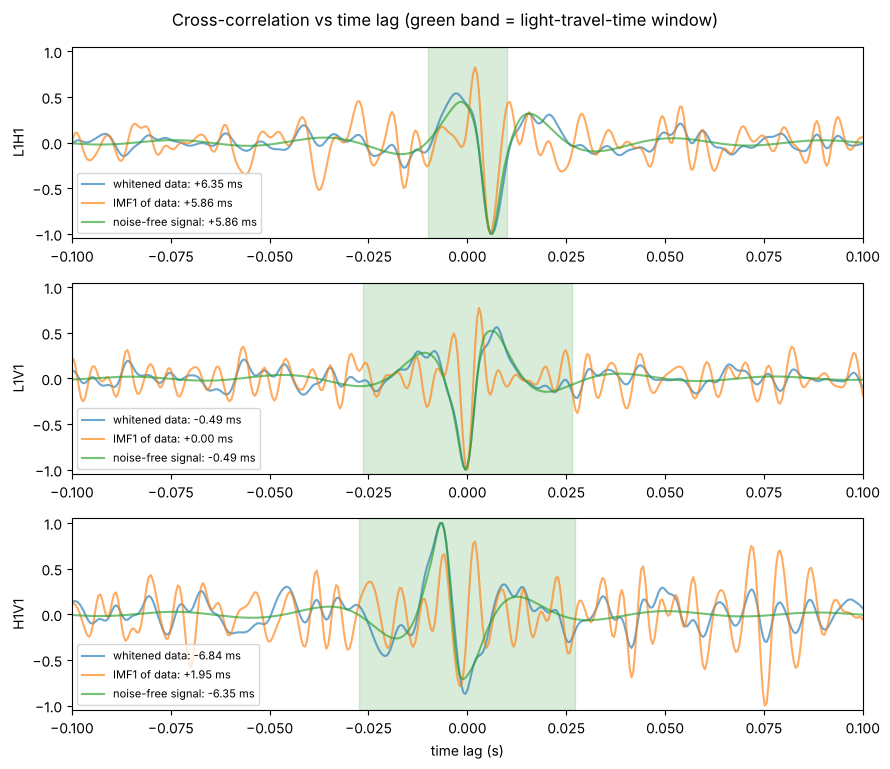

In [3]:
P.plot_xcorr_pairs(a["curves"], labels={"data": "whitened data", "imf1": "IMF1 of data", "signal": "noise-free signal"})
plt.show()

In [4]:
print(f"{'pair':6s} {'signal (ref)':>13s} {'data':>9s} {'IMF1':>9s}   [ms]")
for a_, b_ in cfg.pairs():
    p = a_ + b_
    print(f"{p:6s} {m['lag_signal_'+p]:13.2f} {m['lag_data_'+p]:9.2f} {m['lag_imf1_'+p]:9.2f}")
print(f"\nsampling resolution: {1e3/cfg.fsamp:.2f} ms")

pair    signal (ref)      data      IMF1   [ms]
L1H1            5.86      6.35      5.86
L1V1           -0.49     -0.49      0.00
H1V1           -6.35     -6.84      1.95

sampling resolution: 0.49 ms


**Note.** One noise realisation says little about whether IMF1 helps. The benchmark in notebook 04 repeats this over many
noise seeds and SNRs.